# Population Dynamics: Malthus, Verhulst and Leslie on Brazil's Real Data

# Introduction: Topic and Rationale

Population dynamics is the branch of biology and mathematics that studies how the number of individuals in a population changes over time. Understanding these changes matters not only for ecology but also for the economic and social planning of nations.

The ability to predict the future size of a population is crucial for strategic decisions. Governments need to know how many citizens there will be in order to plan pension systems and build schools, hospitals, and urban infrastructure.

This notebook compares three classic models on **Brazil's real population data**, taken from the United Nations World Population Prospects 2024: the exponential model (Malthus), the logistic model (Verhulst) and the age-structured Leslie matrix. Each model is judged the way a forecaster would be: **fitted on the past and tested on years it did not see**.

**What changed from the first version.** The first version used synthetic data generated inside the notebook, so it could show how the models behave, but not whether they work. This version adds three things:
1. an out-of-sample test: Malthus and Verhulst are fitted on 1950-2000 and asked to forecast 2001-2023;
2. a Leslie matrix built from real fertility rates and life tables, tested by projecting 2000 to 2020;
3. a comparison with the UN's own projection to 2100 and its 95% interval.

### Model Comparison (Expectations)

| Model | Factors Considered | What It Ignores | Degree of Realism |
| :--- | :--- | :--- | :--- |
| **Exponential** | Births, deaths. | Environmental limits, age, economy. | Low |
| **Logistic** | + Resources, space, competition. | Age differences, social change. | Medium |
| **Leslie matrix** | + Age, sex, age-specific fertility. | Behavioral change over time. | Medium |
| **Variable Leslie (UN, IBGE)** | + Projected fertility, mortality and migration. | Almost nothing (tries to model everything through assumptions). | **High** |

# Data: UN World Population Prospects 2024

All data come from [World Population Prospects 2024](https://population.un.org/wpp/), the UN's official estimates and projections for every country. The four files in `data/` are the Brazil rows of the UN's CSV files, downloaded and filtered by `data/download_wpp.py`:

| File | Content | Years |
| :--- | :--- | :--- |
| `brazil_total_population.csv` | Total, male and female population: medium, low and high variants and the 95% prediction interval | 1950-2100 |
| `brazil_population_by_age.csv` | Population by sex and 5-year age group (0-4 to 100+) | 1950-2100 |
| `brazil_fertility_by_age.csv` | Age-specific fertility rates (births per 1,000 women per year), medium variant | 1950-2100 |
| `brazil_life_table_female.csv` | Abridged female life table ($l_x$, $L_x$, $T_x$, life expectancy) | 1950-2023 |

Two cautions. Values up to 2023 are **estimates**: the UN rebuilds them from censuses, surveys and civil registration, so they are the best reconstruction available, not raw counts. Values after 2023 are **projections**. They are used here only as a reference to compare against, never to fit the models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from scipy.optimize import curve_fit

plt.style.use('dark_background')
BACKGROUND = '#1e1e1e'
CYAN, PINK, GREEN, YELLOW = '#00e5ff', '#ff0055', '#39ff14', '#ffd60a'
plt.rcParams.update({'figure.facecolor': BACKGROUND, 'axes.facecolor': BACKGROUND,
                     'savefig.facecolor': BACKGROUND, 'axes.grid': True, 'grid.alpha': 0.15,
                     'font.size': 11, 'legend.frameon': False})
millions = mticker.FuncFormatter(lambda x, _: f'{x / 1e6:.0f}M')
Path('figures').mkdir(exist_ok=True)

total = pd.read_csv('data/brazil_total_population.csv')
by_age = pd.read_csv('data/brazil_population_by_age.csv')
fertility = pd.read_csv('data/brazil_fertility_by_age.csv')
life_table = pd.read_csv('data/brazil_life_table_female.csv')

# WPP reports people in thousands
variant = {name: group.set_index('Time')['PopTotal'] * 1000 for name, group in total.groupby('Variant')}
female = total[total['Variant'] == 'Medium'].set_index('Time')['PopFemale'] * 1000
medium = variant['Medium']
estimates = medium.loc[1950:2023]    # UN estimates, rebuilt from censuses, surveys and civil registration
low95, high95 = variant['Lower 95 PI'], variant['Upper 95 PI']

summary = pd.DataFrame({
    'Population (M)': medium.loc[[1950, 2000, 2023, 2050, 2100]] / 1e6,
    '95% interval (M)': ['', '', '',
                         f'{low95[2050] / 1e6:.0f} to {high95[2050] / 1e6:.0f}',
                         f'{low95[2100] / 1e6:.0f} to {high95[2100] / 1e6:.0f}'],
    'Type': ['Estimate', 'Estimate', 'Estimate', 'Projection', 'Projection'],
}).round(1)
print(f'Peak of the medium variant: {medium.max() / 1e6:.1f} million in {medium.idxmax()}')
summary

Peak of the medium variant: 219.3 million in 2042


,Population (M),95% interval (M),Type
Time,,,
1950,53.4,,Estimate
2000,174.0,,Estimate
2023,211.1,,Estimate
2050,217.5,196 to 236,Projection
2100,163.4,101 to 236,Projection


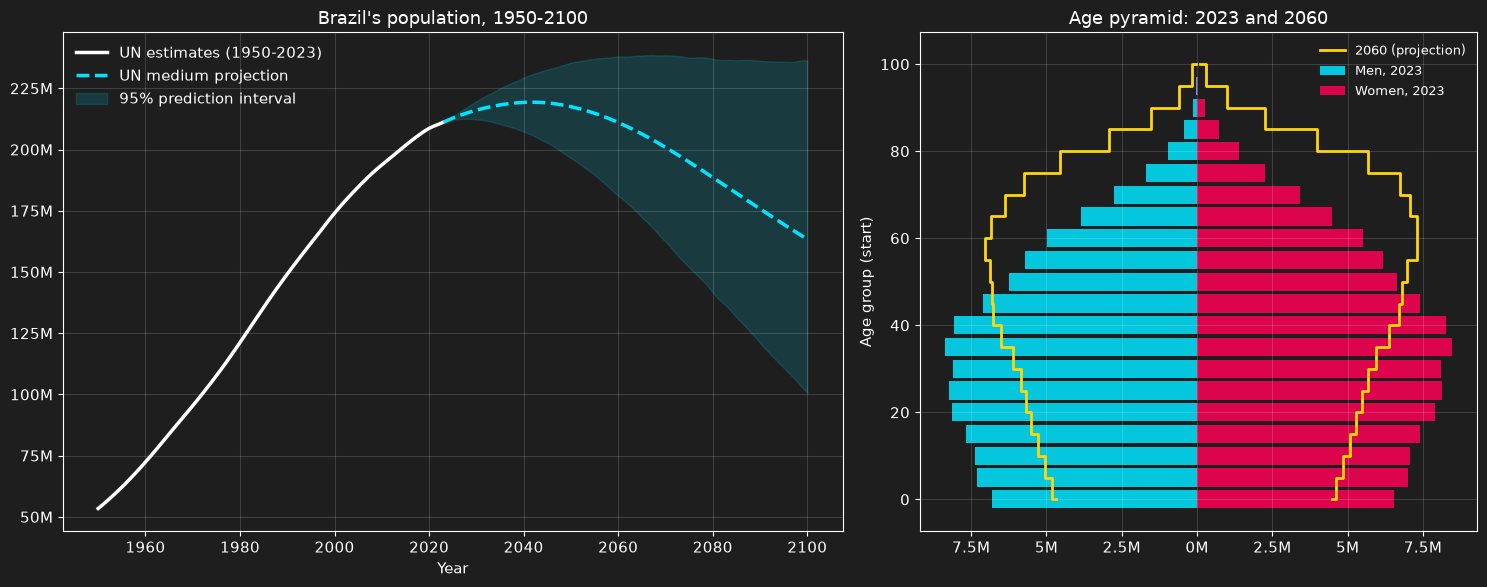

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.4, 1]})

ax1.plot(estimates.index, estimates, color='white', lw=2.5, label='UN estimates (1950-2023)')
proj = medium.loc[2023:]
ax1.plot(proj.index, proj, color=CYAN, lw=2.5, ls='--', label='UN medium projection')
ax1.fill_between(low95.loc[2024:].index, low95.loc[2024:], high95.loc[2024:], color=CYAN, alpha=0.15,
                 label='95% prediction interval')
ax1.yaxis.set_major_formatter(millions)
ax1.set_title("Brazil's population, 1950-2100")
ax1.set_xlabel('Year')
ax1.legend(loc='upper left')

groups = by_age[by_age['Time'] == 2023].sort_values('AgeGrpStart')
future = by_age[by_age['Time'] == 2060].sort_values('AgeGrpStart')
y = groups['AgeGrpStart']
ax2.barh(y, -groups['PopMale'] / 1e3, height=4.2, color=CYAN, alpha=0.85, label='Men, 2023')
ax2.barh(y, groups['PopFemale'] / 1e3, height=4.2, color=PINK, alpha=0.85, label='Women, 2023')
ax2.step(-future['PopMale'] / 1e3, y, where='mid', color=YELLOW, lw=2, label='2060 (projection)')
ax2.step(future['PopFemale'] / 1e3, y, where='mid', color=YELLOW, lw=2)
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{abs(x):g}M'))
ax2.set_title('Age pyramid: 2023 and 2060')
ax2.set_ylabel('Age group (start)')
ax2.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('figures/population_and_pyramid.png', dpi=120)
plt.show()

### How to read the results

- Brazil grew from 53 million people in 1950 to 211 million in 2023, but the curve has been bending since the 1980s.
- The UN medium variant has the population peaking at 219 million in 2042 and falling to 163 million in 2100. The 95% interval for 2100 is wide, from 101 to 236 million.
- The pyramid shows why. In 2023 the base is already narrower than the middle: there are fewer children than young adults. By 2060 the shape is close to inverted, with more people in their 60s than children. A model that ignores age cannot see this coming.

# Exponential Growth (Malthus)

## Theoretical Background

The exponential model is the most basic approach in population dynamics, proposed by Thomas Malthus in 1798. It assumes that, in an environment with unlimited resources, a population's growth rate is proportional to its current size.

Mathematically, this is described by the first-order linear ordinary differential equation (ODE):

$$\frac{dN}{dt} = rN$$

Where:
*   $N(t)$ is the population at time $t$;
*   $r$ is the intrinsic per capita growth rate (births minus deaths).

The analytical solution of this equation, given an initial population $N_0$, is:

$$N(t) = N_0 e^{r(t - t_0)}$$

### Goal of This Section
Here we fit this model to the project's simulated demographic data to estimate the rate $r$ and check how well Malthusian growth matches the proposed dynamics.

## Out-of-Sample Test

A model that fits the past well can still forecast badly. To check, each model is fitted only on **1950-2000** and then asked to forecast **2001-2023**, years it never saw. The error is measured as a percentage of the UN estimate.

As a benchmark, the test also includes a straight line through 1991-2000. A model that cannot beat a ruler is not adding much.

In [3]:
TRAIN_END = 2000
train = estimates.loc[:TRAIN_END]
test = estimates.loc[TRAIN_END + 1:]
t_train = train.index.to_numpy() - 1950
t_test = test.index.to_numpy() - 1950


def exponential(t, P0, r):
    return P0 * np.exp(r * t)


(P0_exp, r_exp), _ = curve_fit(exponential, t_train, train.to_numpy(), p0=[50e6, 0.02])
pred_exp = exponential(t_test, P0_exp, r_exp)


def forecast_errors(name, prediction):
    pct = (prediction - test.to_numpy()) / test.to_numpy() * 100
    return {'Model': name, 'Mean absolute error 2001-2023 (%)': np.abs(pct).mean(),
            'Error in 2023 (%)': pct[-1], 'Forecast for 2023 (M)': prediction[-1] / 1e6}


print(f'Growth rate fitted on 1950-2000: r = {r_exp:.2%} per year '
      f'(the population doubles every {np.log(2) / r_exp:.0f} years)')
pd.DataFrame([forecast_errors('Exponential (Malthus)', pred_exp)]).round(1)

Growth rate fitted on 1950-2000: r = 2.24% per year (the population doubles every 31 years)


,Model,Mean absolute error 2001-2023 (%),Error in 2023 (%),Forecast for 2023 (M)
0,Exponential (Malthus),23.0,45.2,306.6


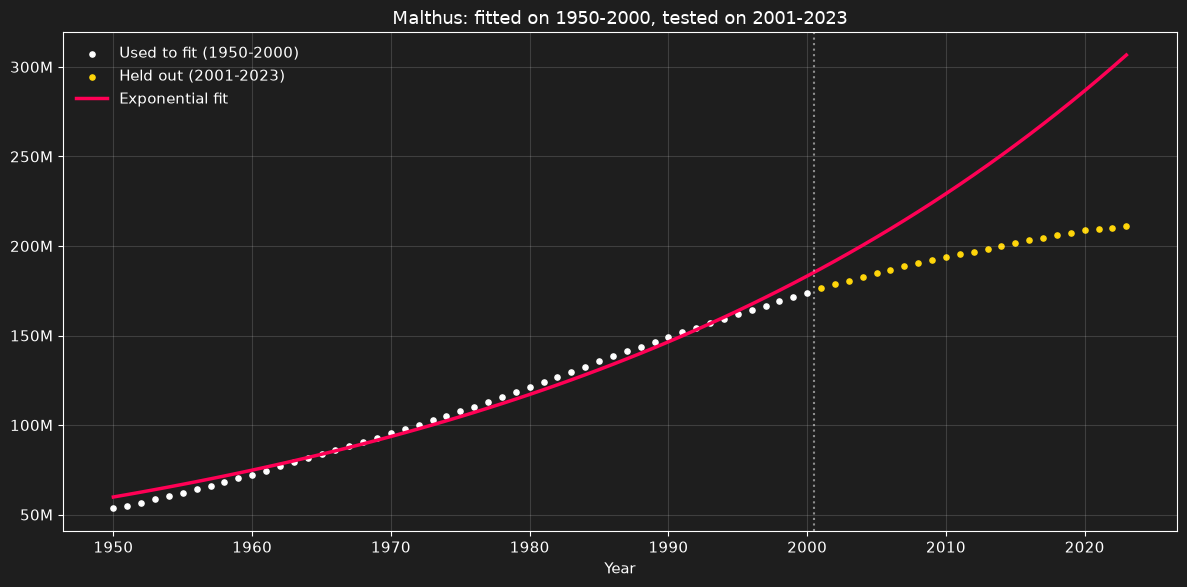

In [4]:
t_all = np.arange(0, 2023 - 1950 + 1)
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(train.index, train, s=14, color='white', label='Used to fit (1950-2000)')
ax.scatter(test.index, test, s=14, color=YELLOW, label='Held out (2001-2023)')
ax.plot(t_all + 1950, exponential(t_all, P0_exp, r_exp), color=PINK, lw=2.5, label='Exponential fit')
ax.axvline(TRAIN_END + 0.5, color='white', ls=':', alpha=0.5)
ax.yaxis.set_major_formatter(millions)
ax.set_title('Malthus: fitted on 1950-2000, tested on 2001-2023')
ax.set_xlabel('Year')
ax.legend()
plt.tight_layout()
plt.show()

## Discussion of Results: Exponential Model

### The fallacy of infinite growth

Fitted on 1950-2000, the exponential model finds a growth rate of 2.24% per year, which doubles the population every 31 years. That rate describes the 1950s and 1960s, but Brazil's growth had slowed a lot by the 1990s. As a result, the model forecasts 307 million people for 2023, against 211 million in reality: an error of 45%. The average error over 2001-2023 is 23%.

The problem is structural, not a matter of tuning: with a constant rate, the curve cannot bend.

# Logistic Growth (Verhulst)

### **Theoretical Background**

The logistic model, proposed by Pierre-François Verhulst in 1838, extends Malthus's exponential model by including **environmental limits**.

The central idea is that, as the population grows, resource constraints appear (food, space, infrastructure, and so on), so the growth rate **stops being proportional only to population size** and also depends on **how close the population is to a maximum limit**, called the **carrying capacity** $K$.

This behavior is described by the following nonlinear ordinary differential equation (ODE):

$$
\frac{dN}{dt} = r \, N \left(1 - \frac{N}{K}\right)
$$

**Where:**
*   $N(t)$ is the population at time $t$;
*   $r$ is the intrinsic per capita growth rate;
*   $K$ is the environment's **carrying capacity**;
*   The term $ \left(1 - \frac{N}{K}\right) $ represents the **brake** imposed by competition for resources.

**Qualitative interpretation:**
*   **When $N \ll K$:** $1 - \frac{N}{K} \approx 1$ → growth is **almost exponential** (as in Malthus).
*   **When $N$ approaches $K$:** $1 - \frac{N}{K} \to 0$ → the growth rate **decreases**.
*   **If $N > K$:** $1 - \frac{N}{K} < 0$ → the population tends to **shrink** until it returns to a sustainable range.

### **Analytical Solution**

Given an initial population $N_0 = N(t_0)$, the analytical solution of the logistic model is:

$$
N(t) = \frac{K}{1 + \left(\frac{K - N_0}{N_0}\right) e^{-r (t - t_0)}}
$$

This expression produces a **sigmoid (S-shaped)** curve with three main phases:

1.  **Initial phase (almost exponential):** fast growth, with little environmental limitation.
2.  **Deceleration phase:** the effect of competition increases and the growth rate falls.
3.  **Plateau:** the population stabilizes around $K$.

An important feature of the model is the **inflection point**, where the total growth rate $\frac{dN}{dt}$ is highest. At this point:
*   The population is: $N_{\text{inf}} = \frac{K}{2}$
*   The maximum growth rate is: $\left.\frac{dN}{dt}\right|_{N = K/2} = \frac{rK}{4}$

### **Goal of This Section**

Here we apply the logistic model to the project's **simulated demographic data**, using the total population from `population.csv`.

**The main goals are:**

*   Fit the parameters $r$ (intrinsic rate) and $K$ (carrying capacity) to the simulated historical data.
*   Identify the **inflection point** of population growth in the context of the model.
*   Compare logistic behavior with **Malthusian exponential** growth and discuss how much a carrying capacity makes the long-term projection more realistic.

In [5]:
def logistic(t, P0, r, K):
    return K / (1 + (K - P0) / P0 * np.exp(-r * t))


(P0_log, r_log, K_log), _ = curve_fit(logistic, t_train, train.to_numpy(), p0=[50e6, 0.03, 300e6], maxfev=20000)
pred_log = logistic(t_test, P0_log, r_log, K_log)

# Naive benchmark: extend the straight line of the last ten years before the cut
slope, intercept = np.polyfit(train.loc[1991:].index, train.loc[1991:], 1)
pred_line = slope * test.index.to_numpy() + intercept

print(f'Logistic fitted on 1950-2000: r = {r_log:.2%} per year, carrying capacity K = {K_log / 1e6:.0f} million')
errors = pd.DataFrame([forecast_errors('Exponential (Malthus)', pred_exp),
                       forecast_errors('Logistic (Verhulst)', pred_log),
                       forecast_errors('Straight line of 1991-2000 (benchmark)', pred_line)]).round(1)
errors

Logistic fitted on 1950-2000: r = 4.03% per year, carrying capacity K = 269 million


,Model,Mean absolute error 2001-2023 (%),Error in 2023 (%),Forecast for 2023 (M)
0,Exponential (Malthus),23.0,45.2,306.6
1,Logistic (Verhulst),2.4,5.0,221.7
2,Straight line of 1991-2000 (benchmark),3.8,9.4,231.1


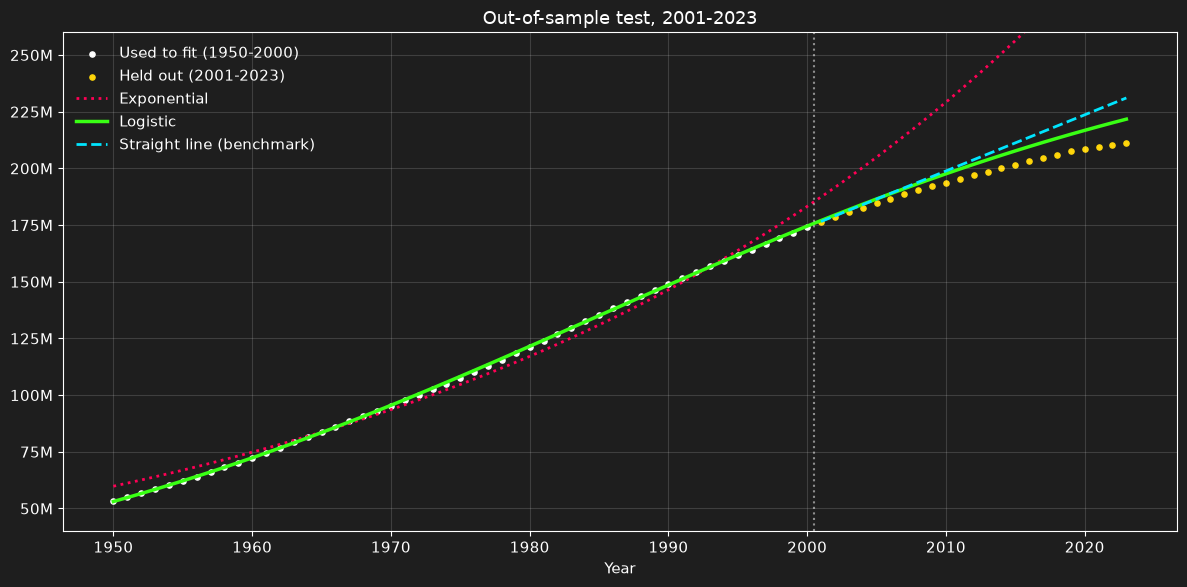

In [6]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(train.index, train, s=14, color='white', label='Used to fit (1950-2000)')
ax.scatter(test.index, test, s=14, color=YELLOW, label='Held out (2001-2023)')
ax.plot(t_all + 1950, exponential(t_all, P0_exp, r_exp), color=PINK, lw=2, ls=':', label='Exponential')
ax.plot(t_all + 1950, logistic(t_all, P0_log, r_log, K_log), color=GREEN, lw=2.5, label='Logistic')
ax.plot(test.index, pred_line, color=CYAN, lw=2, ls='--', label='Straight line (benchmark)')
ax.axvline(TRAIN_END + 0.5, color='white', ls=':', alpha=0.5)
ax.set_ylim(40e6, 260e6)
ax.yaxis.set_major_formatter(millions)
ax.set_title('Out-of-sample test, 2001-2023')
ax.set_xlabel('Year')
ax.legend()
plt.tight_layout()
plt.savefig('figures/out_of_sample_test.png', dpi=120)
plt.show()

## Results: Logistic Model (Verhulst)

### A large improvement, for the right reason

With a ceiling $K$, the logistic curve bends the way Brazil's population did. Fitted on 1950-2000, it estimates $K$ = 269 million and forecasts 222 million for 2023: an error of 5.0%, with an average error of 2.4% over 2001-2023. It beats the straight-line benchmark (3.8% average error), so it adds real information.

### But the ceiling is a fitted number, not a cause

$K$ is not measured anywhere. It is whatever value makes the curve fit, and it moves when the data change: refitting on 1950-2023 lowers it to 246 million (see the Model Comparison section).

The logistic also has a deeper limit. Its only stable state is $K$, so it can slow growth but **never produce a decline**. Brazil's decline is expected to come from fertility below replacement, not from running out of space or resources, and that mechanism lives in the age structure. That is the job of the Leslie matrix.

# Matrix Model

Let $N(t) = \begin{bmatrix}
    n_1(t) \\
    n_2(t) \\
    \vdots \\
    n_k(t)
\end{bmatrix}$

Where $n_i(t)$ is the population in the $i$-th age group at time $t$.

Population dynamics are then described as a discrete linear dynamical system. The population at the next time step, $N(t+1)$, is obtained by multiplying the current population vector, $N(t)$, by a transition matrix $L$, known as the Leslie matrix:

\begin{equation}
    N(t+1) = L \cdot N(t)
\end{equation}


All the complexity of demographic dynamics (births, deaths, and aging) is contained in the structure of the matrix $L$.

**The Structure of the Leslie Matrix (L):**

The matrix $L$ is a $k \times k$ matrix with two types of vital parameters:

*  **Fertility Rates ($f_i$):** Located in the first row of the matrix. The value $f_i$ is the average number of (female) offspring that an individual in age group $i$ will produce during the interval from $t$ to $t+1$. Note that $f_i$ is zero for pre-reproductive and post-reproductive age groups.
    
*  **Survival Rates ($s_i$):** Located on the main subdiagonal. The value $s_i$ is the probability that an individual in age group $i$ survives and moves to age group $i+1$ at the next time step.

The general form of the Leslie matrix is:

$L = \begin{bmatrix}
    f_1 & f_2 & f_3 & \dots & f_{k-1} & f_k \\
    s_1 & 0   & 0   & \dots & 0       & 0   \\
    0   & s_2 & 0   & \dots & 0       & 0   \\
    \vdots & \vdots & \ddots & & \vdots & \vdots \\
    0   & 0   & 0   & \dots & s_{k-1} & 0
\end{bmatrix}$


Advantages of the Leslie model:

This approach is fundamentally superior to aggregate models for projecting human populations because:

*  **It simulates aging:** "Moving" the population along the subdiagonal ($s_i$) naturally simulates population aging, allowing age analysis.
    
*  **Time-varying parameters:** The logistic model was tied to a constant $r$. In the Leslie model, the parameters $f_i$ and $s_i$ can change at each time step. We can reduce the values of $f_i$ in the matrix $L$ during the simulation to reflect falling fertility, which allows the model to correctly predict deceleration and eventual population shrinkage, something impossible for the logistic model.
    
*  **Demographic realism:** This model is the theoretical basis for modern population projections, including those produced by institutions such as IBGE and the UN.

## Variables

This section lists where each input of the matrix comes from and how it is transformed.

### Raw data

* **`female_population(year)`** (initial state, $N_0$): women in each of the 21 age groups (0-4 to 100+) in the base year, from `brazil_population_by_age.csv`. The model follows **women only**, the standard choice in demography: births depend on the number of mothers, and men are added back at the end with the observed sex ratio.
* **`fertility_rates(year)`** ($f_i$): age-specific fertility rates, in births per woman per year, for each 5-year group from 15-19 to 45-49.
* **`life_table`** ($l_x$, $L_x$, $T_x$): the female life table. $l_x$ is how many of 100,000 newborn girls reach age $x$, $L_x$ is the number of years they live inside the age group, and $T_x$ is the number of years they live from age $x$ onward.

### Model parameters

* **5-year step:** the age groups span 5 years, so each multiplication by the matrix moves the population forward 5 years.
* **`FEMALE_SHARE_AT_BIRTH = 1 / 2.05`:** about 105 boys are born for every 100 girls, so 48.8% of births are girls. The first version multiplied by the share of women in the whole population (51.5%), which mixes up two different things.

### Matrix entries

* **Survival (subdiagonal):** $s_i = L_{i+1} / L_i$, the share of women in group $i$ who will be alive in group $i+1$ five years later. For the open group 100+, $s = T_{100} / T_{95}$.
* **Fertility (first row):**
$$F_i = \frac{L_{0-4}}{2\,l_0}\,\left(f_i + s_i f_{i+1}\right) \cdot 0.488$$
Over the 5 years, women in group $i$ spend part of the time at their current fertility and part at the next group's, hence the average of $f_i$ and $s_i f_{i+1}$. The factor $L_{0-4}/l_0$ turns births into girls who survive to be counted in group 0-4.

## Deriving the Matrix Product ($N_{t+1} = L \cdot N_t$)

Population dynamics in the model are given by multiplying the transition matrix $L$ by the current population vector $N_t$. Expanding the matrix product clearly shows the biological origin of each term.

$$
\begin{bmatrix} n_1(t+1) \\ n_2(t+1) \\ \vdots \\ n_k(t+1) \end{bmatrix}
=
\begin{bmatrix}
f_1 & f_2 & \dots & f_k \\
s_1 & 0 & \dots & 0 \\
0 & s_2 & \dots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \dots & 0
\end{bmatrix}
\cdot
\begin{bmatrix} n_1(t) \\ n_2(t) \\ \vdots \\ n_k(t) \end{bmatrix}
$$

Multiplying row by column gives:

**1. The first row (births):**
The new generation ($n_1$) is the sum of the children of all mothers of all ages:

$$
n_1(t+1) = \underbrace{f_1 n_1(t)}_{\substack{\text{Children of} \\ \text{age group 0-4}}} + \underbrace{f_2 n_2(t)}_{\substack{\text{Children of} \\ \text{age group 5-9}}} + \dots + \underbrace{f_k n_k(t)}_{\substack{\text{Children of} \\ \text{age group 100+}}}
$$

**2. The other rows (aging):**
The next age group ($n_{i+1}$) comes only from those who survived the previous group:

$$
n_{i+1}(t+1) = \underbrace{s_i}_{\substack{\text{Chance of} \\ \text{Surviving}}} \cdot \underbrace{n_i(t)}_{\substack{\text{Previous} \\ \text{Population}}}
$$

## Discussion of the Time Interval ($\Delta t$)

The choice of age group interval ($n$) is a fundamental decision in this model, because it sets the **simulation's time step**. The model assumes that, after one time step $t \to t+1$, an individual who survives in age group $i$ must move to age group $i+1$. Therefore, the simulation's time step must be **identical** to the width of the age group. If demographic data are collected in 5-year groups (0-4, 5-9, etc.), the model must project the population every 5 years.

* **Very short intervals (e.g., 1 year):** These offer high temporal resolution and capture fast changes, but they require extremely detailed data, which often contain statistical noise or are unavailable. They also produce very large matrices, increasing the computational cost.

* **Very long intervals (e.g., 15 or 20 years):** These simplify the model but lose the information needed to capture biological nuances, such as how fertility varies within the reproductive period (a 20-year-old woman has very different fertility from a 35-year-old woman, and grouping them loses that information).

* **The convention (5 years):** The international standard (adopted by IBGE and the UN) is a **5-year** interval. It offers the ideal balance: it smooths irrelevant annual fluctuations, aligns with the typical frequency of censuses, and adequately captures the phases of the human life cycle.

## Theoretical Basis of the Survival Rate ($s_i$)

The first version estimated survival from death rates with the uniform-deaths approximation, $s_i = (1 - \frac{n}{2} m_i) / (1 + \frac{n}{2} m_i)$. That works for adults but is poor for babies, because deaths in the first year concentrate in the first weeks of life.

With real data there is a better option. The life table already contains $L_x$, the years lived inside each age group, which accounts for when deaths happen within the group. The survival ratio between two consecutive groups is then

$$s_i = \frac{{}_5L_{x+5}}{{}_5L_x}$$

the same ratio used in official projections (Preston, Heuveline and Guillot, 2001). The life table splits the first group into ages 0 and 1-4, so the code adds the two to get ${}_5L_0$.

## Applying the Model to Real Data

The functions below build the matrix for any year from 1950 to 2023. `project` multiplies it forward in 5-year steps, either holding the rates of one year fixed or using the rates of the middle of each period (for example, the 2002 rates for 2000-2005).

Two numbers summarize the 2023 matrix:
- the **total fertility rate**, the number of children a woman would have at that year's rates;
- the **dominant eigenvalue** $\lambda$, the growth factor the population converges to if the rates never change. Above 1 the population grows; below 1 it shrinks.

In [7]:
AGE_GROUPS = 21                          # 0-4, 5-9, ..., 95-99, 100+
FEMALE_SHARE_AT_BIRTH = 1 / (1 + 1.05)   # about 105 boys are born for every 100 girls


def female_population(year):
    rows = by_age[by_age['Time'] == year].sort_values('AgeGrpStart')
    return rows['PopFemale'].to_numpy() * 1000


def survival_ratios(year):
    rows = life_table[life_table['Time'] == year].sort_values('AgeGrpStart')
    L, T, l0 = rows['Lx'].to_numpy(), rows['Tx'].to_numpy(), rows['lx'].iloc[0]
    L5 = np.concatenate([[L[0] + L[1]], L[2:]])   # join the "0" and "1-4" rows into 0-4
    T5 = np.concatenate([[T[0]], T[2:]])
    s = np.empty(AGE_GROUPS)
    s[:-2] = L5[1:-1] / L5[:-2]
    s[-2] = s[-1] = T5[-1] / T5[-2]               # open age group 100+
    return s, L5[0], l0


def fertility_rates(year):
    rows = fertility[fertility['Time'] == year]
    f = np.zeros(AGE_GROUPS)
    f[(rows['AgeGrpStart'] // 5).to_numpy()] = rows['ASFR'].to_numpy() / 1000   # births per woman per year
    return f


def leslie_matrix(mortality_year, fertility_year):
    s, L0, l0 = survival_ratios(mortality_year)
    f = fertility_rates(fertility_year)
    M = np.zeros((AGE_GROUPS, AGE_GROUPS))
    M[0, :-1] = L0 / (2 * l0) * (f[:-1] + s[:-1] * f[1:]) * FEMALE_SHARE_AT_BIRTH
    M[np.arange(1, AGE_GROUPS), np.arange(AGE_GROUPS - 1)] = s[:-1]
    M[-1, -1] = s[-1]
    return M


def project(start_year, end_year, rates_year=None):
    """Projects women by age in 5-year steps. rates_year=None uses the rates of the middle of each period."""
    n = female_population(start_year)
    path = {start_year: n}
    for year in range(start_year, end_year, 5):
        rates = year + 2 if rates_year is None else rates_year
        n = leslie_matrix(rates, rates) @ n
        path[year + 5] = n
    return path


M2023 = leslie_matrix(2023, 2023)
lam = np.max(np.abs(np.linalg.eigvals(M2023)))
tfr = fertility_rates(2023).sum() * 5
print(f'Total fertility rate in 2023: {tfr:.2f} children per woman (replacement is about 2.1)')
print(f'Dominant eigenvalue of the 2023 matrix: {lam:.3f} per 5 years '
      f'= {np.log(lam) / 5:.2%} per year in the long run')

Total fertility rate in 2023: 1.62 children per woman (replacement is about 2.1)
Dominant eigenvalue of the 2023 matrix: 0.955 per 5 years = -0.91% per year in the long run


In [8]:
constant = project(2000, 2020, rates_year=2000)
observed = project(2000, 2020)
rows = []
for year in range(2005, 2021, 5):
    actual = female_population(year).sum()
    rows.append({'Year': year, 'UN estimate (M)': actual / 1e6,
                 'Leslie, 2000 rates (M)': constant[year].sum() / 1e6,
                 'Error (%)': (constant[year].sum() / actual - 1) * 100,
                 'Leslie, observed rates (M)': observed[year].sum() / 1e6,
                 'Error, observed rates (%)': (observed[year].sum() / actual - 1) * 100})
backtest = pd.DataFrame(rows).round(2)
backtest

,Year,UN estimate (M),"Leslie, 2000 rates (M)",Error (%),"Leslie, observed rates (M)","Error, observed rates (%)"
0,2005,93.12,93.72,0.65,93.25,0.14
1,2010,97.86,99.83,2.02,98.36,0.52
2,2015,102.09,105.64,3.48,103.08,0.97
3,2020,105.82,110.98,4.88,107.37,1.47


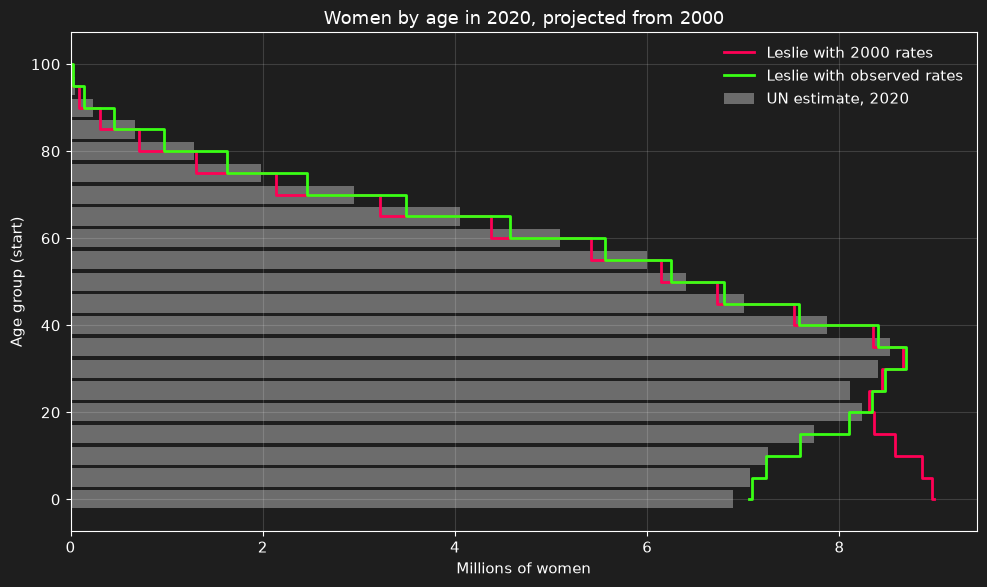

,UN estimate (M),"Leslie, 2000 rates (M)","Leslie, observed rates (M)","Error, 2000 rates (%)","Error, observed rates (%)"
0-14,21.22,26.69,21.53,25.76,1.46
15-64,73.38,74.59,74.66,1.65,1.74
65+,11.21,9.70,11.18,-13.51,-0.33


In [9]:
actual_2020 = female_population(2020)
broad = {'0-14': slice(0, 3), '15-64': slice(3, 13), '65+': slice(13, None)}
by_group = pd.DataFrame({name: {'UN estimate (M)': actual_2020[s].sum() / 1e6,
                                'Leslie, 2000 rates (M)': constant[2020][s].sum() / 1e6,
                                'Leslie, observed rates (M)': observed[2020][s].sum() / 1e6}
                         for name, s in broad.items()}).T
by_group['Error, 2000 rates (%)'] = (by_group['Leslie, 2000 rates (M)'] / by_group['UN estimate (M)'] - 1) * 100
by_group['Error, observed rates (%)'] = (by_group['Leslie, observed rates (M)'] / by_group['UN estimate (M)'] - 1) * 100

fig, ax = plt.subplots(figsize=(10, 6))
ages = np.arange(0, 101, 5)
ax.barh(ages, actual_2020 / 1e6, height=4.2, color='white', alpha=0.35, label='UN estimate, 2020')
ax.step(constant[2020] / 1e6, ages, where='mid', color=PINK, lw=2, label='Leslie with 2000 rates')
ax.step(observed[2020] / 1e6, ages, where='mid', color=GREEN, lw=2, label='Leslie with observed rates')
ax.set_title('Women by age in 2020, projected from 2000')
ax.set_xlabel('Millions of women')
ax.set_ylabel('Age group (start)')
ax.legend()
plt.tight_layout()
plt.savefig('figures/leslie_backtest_2020.png', dpi=120)
plt.show()
by_group.round(2)

### Discussion of Results: Out-of-Sample Test, 2000 to 2020

The test starts from the women counted in 2000 and projects them to 2020, comparing each step with the UN estimate.

- **With the 2000 rates held fixed**, the error grows to 4.9% in 2020. The detail by age shows why: the model has 26% too many girls under 15 and 13% too few women over 65. Between 2000 and 2020, Brazilian women had fewer children and lived longer than in 2000, and a model with frozen rates cannot know that.
- **With the rates each period actually had**, the error drops to 1.5% in 2020 and stays below 2% in every age group. The mechanics of the model are right; what went wrong before was the assumption that rates stay fixed.
- The 1.5% that remains is consistent with what the model leaves out by design, mainly migration: the matrix describes a closed population.

The lesson for forecasting: the Leslie matrix turns assumptions about fertility and mortality into an age structure very accurately, but the forecast is only as good as those assumptions. That is why the UN projects the rates themselves before running the matrix.

## Long-Run Projection to 2100

Now the matrix is run forward from 2023 in two versions. One keeps the 2023 rates fixed; the other uses the UN's projected fertility rates with 2023 mortality. Both are compared with the UN medium variant for women.

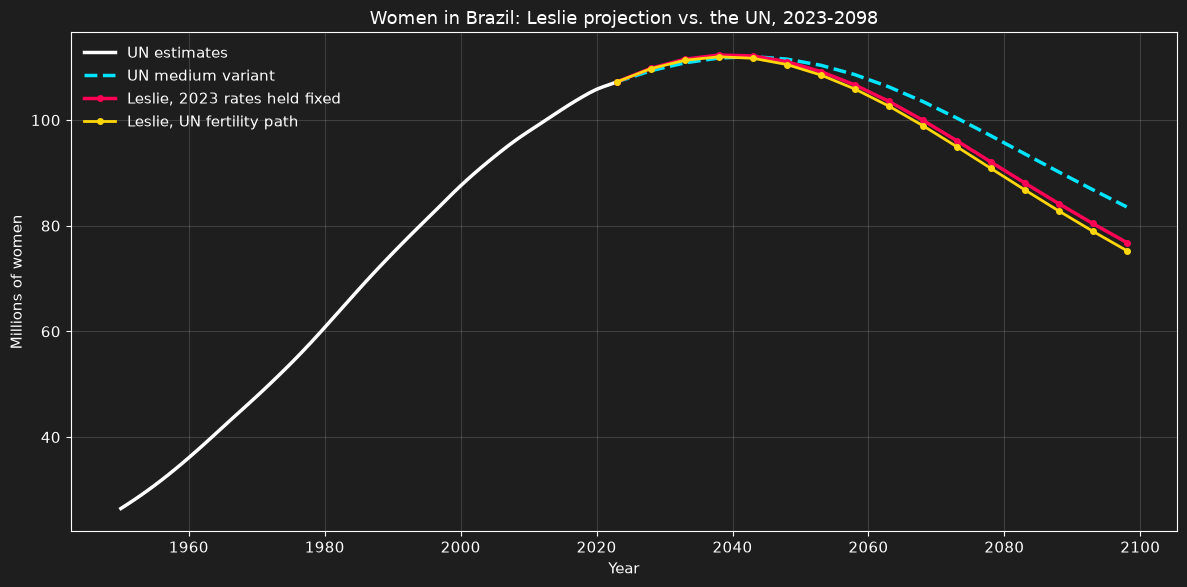

,"Leslie, 2023 rates (M)","Leslie, UN fertility + 2023 mortality (M)",UN medium variant (M),"Share 65+ (Leslie, 2023 rates)"
2023,107.23,107.23,107.23,0.12
2048,111.04,110.51,111.53,0.22
2073,96.08,94.95,100.38,0.28
2098,76.82,75.29,83.57,0.28


In [10]:
n = female_population(2023)
const_path, un_fert_path = {2023: n}, {2023: n}
a, b = n, n
for year in range(2023, 2098, 5):
    a = M2023 @ a
    b = leslie_matrix(2023, year + 2) @ b   # UN fertility path (middle of each period), 2023 mortality
    const_path[year + 5], un_fert_path[year + 5] = a, b

years = np.array(sorted(const_path))
long_run = pd.DataFrame({
    'Leslie, 2023 rates (M)': [const_path[y].sum() / 1e6 for y in years],
    'Leslie, UN fertility + 2023 mortality (M)': [un_fert_path[y].sum() / 1e6 for y in years],
    'UN medium variant (M)': female.loc[years].to_numpy() / 1e6,
}, index=years)
long_run['Share 65+ (Leslie, 2023 rates)'] = [const_path[y][13:].sum() / const_path[y].sum() for y in years]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(female.loc[1950:2023].index, female.loc[1950:2023] / 1e6, color='white', lw=2.5, label='UN estimates')
ax.plot(years, long_run.iloc[:, 2], color=CYAN, lw=2.5, ls='--', label='UN medium variant')
ax.plot(years, long_run.iloc[:, 0], color=PINK, lw=2.5, marker='o', ms=4, label='Leslie, 2023 rates held fixed')
ax.plot(years, long_run.iloc[:, 1], color=YELLOW, lw=2, marker='o', ms=4, label='Leslie, UN fertility path')
ax.set_title('Women in Brazil: Leslie projection vs. the UN, 2023-2098')
ax.set_ylabel('Millions of women')
ax.set_xlabel('Year')
ax.legend()
plt.tight_layout()
plt.show()
long_run.loc[[2023, 2048, 2073, 2098]].round(2)

### Discussion of Results

- **Fertility is already below replacement.** In 2023 Brazilian women had 1.62 children each on average, against about 2.1 needed to replace a generation. The dominant eigenvalue of the 2023 matrix is 0.955 per 5 years, a long-run decline of 0.91% per year.
- **The decline does not start right away.** The large generations born before 2000 are still of childbearing age, so there are still 111 million women in 2048, more than the 107 million of 2023. Only then does the number fall, to 77 million in 2098. Demographers call this delay population momentum. The logistic curve has no way to produce it.
- **Aging is the strongest result.** With 2023 rates, the share of women aged 65 or more goes from 12% in 2023 to 28% in 2073.
- **Comparison with the UN.** Using the UN's fertility path changes almost nothing (75 million in 2098), because the UN expects fertility to stay near 1.6. The gap to the UN's 84 million comes from mortality: the UN assumes life expectancy keeps rising, while this projection freezes it at 2023 levels.

# Model Comparison

Finally, the three models are projected from 2023 to 2100 next to the UN projection. Here Malthus and Verhulst are refitted on all the estimates (1950-2023), and the Leslie projection of women is converted to the whole population with the 2023 ratio of total population to women.

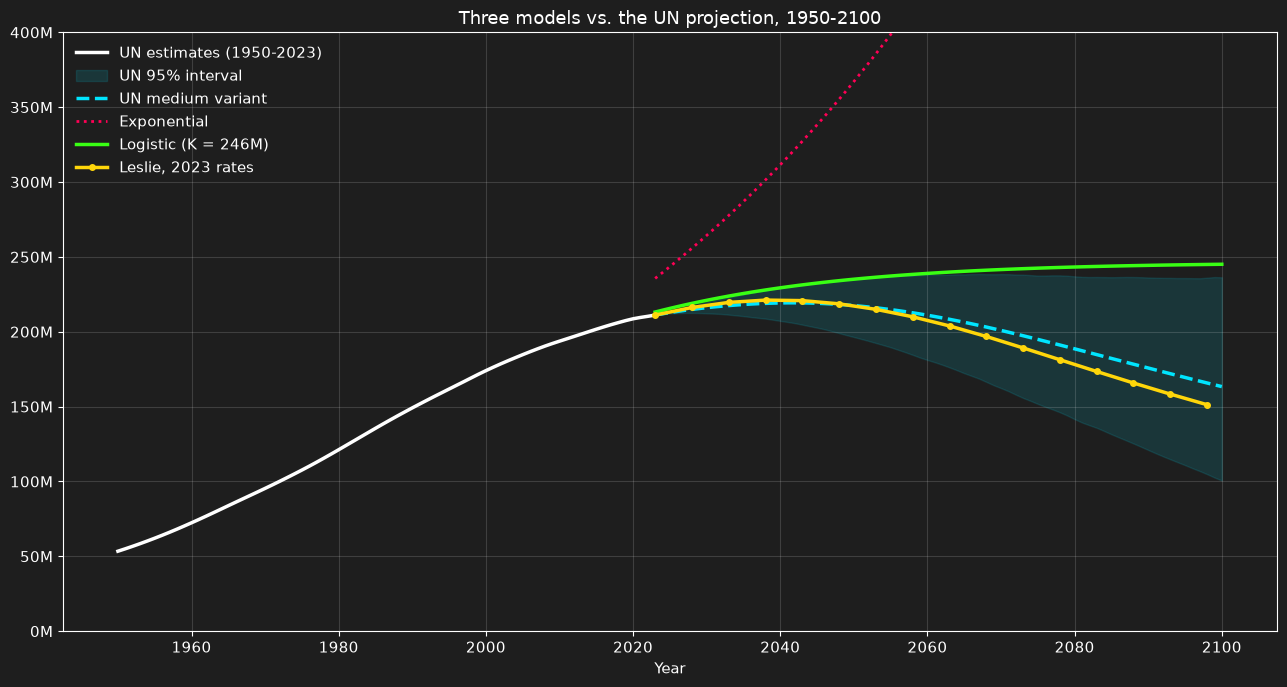

,Exponential (M),Logistic (M),"Leslie, 2023 rates (M)",UN medium (M),UN 95% interval (M)
2050 (Leslie: 2048),367.1,235.1,218.7,217.5,196 to 236
2100 (Leslie: 2098),834.6,245.1,151.3,163.4,101 to 236


In [11]:
t_full = estimates.index.to_numpy() - 1950
(P0_e, r_e), _ = curve_fit(exponential, t_full, estimates.to_numpy(), p0=[50e6, 0.02])
(P0_l, r_l, K_l), _ = curve_fit(logistic, t_full, estimates.to_numpy(), p0=[50e6, 0.03, 250e6], maxfev=20000)
future_years = np.arange(2023, 2101)
t_future = future_years - 1950

to_total = medium[2023] / female[2023]   # women are about 51% of the population
leslie_total = pd.Series([const_path[y].sum() * to_total for y in years], index=years)

fig, ax = plt.subplots(figsize=(13, 7))
ax.plot(estimates.index, estimates, color='white', lw=2.5, label='UN estimates (1950-2023)')
ax.fill_between(low95.loc[2024:].index, low95.loc[2024:], high95.loc[2024:], color=CYAN, alpha=0.12,
                label='UN 95% interval')
ax.plot(medium.loc[2023:].index, medium.loc[2023:], color=CYAN, lw=2.5, ls='--', label='UN medium variant')
ax.plot(future_years, exponential(t_future, P0_e, r_e), color=PINK, lw=2, ls=':', label='Exponential')
ax.plot(future_years, logistic(t_future, P0_l, r_l, K_l), color=GREEN, lw=2.5,
        label=f'Logistic (K = {K_l / 1e6:.0f}M)')
ax.plot(years, leslie_total, color=YELLOW, lw=2.5, marker='o', ms=4, label='Leslie, 2023 rates')
ax.set_ylim(0, 400e6)
ax.yaxis.set_major_formatter(millions)
ax.set_title('Three models vs. the UN projection, 1950-2100')
ax.set_xlabel('Year')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=120)
plt.show()

pd.DataFrame({
    'Exponential (M)': [exponential(y - 1950, P0_e, r_e) / 1e6 for y in (2050, 2100)],
    'Logistic (M)': [logistic(y - 1950, P0_l, r_l, K_l) / 1e6 for y in (2050, 2100)],
    'Leslie, 2023 rates (M)': [leslie_total.loc[2048] / 1e6, leslie_total.loc[2098] / 1e6],
    'UN medium (M)': [medium[2050] / 1e6, medium[2100] / 1e6],
    'UN 95% interval (M)': [f'{low95[2050] / 1e6:.0f} to {high95[2050] / 1e6:.0f}',
                            f'{low95[2100] / 1e6:.0f} to {high95[2100] / 1e6:.0f}'],
}, index=['2050 (Leslie: 2048)', '2100 (Leslie: 2098)']).round(1)

### Conclusion and Model Limitations

| Model | Out-of-sample test | Projection for 2100 | Verdict |
| :--- | :--- | :--- | :--- |
| **Exponential** | 45% error in 2023 (fitted on 1950-2000) | 835 million | Useless beyond a few years |
| **Logistic** | 5% error in 2023, better than the straight line | 245 million, above the UN 95% interval | Good for short horizons, but cannot decline |
| **Leslie, 2023 rates** | 1.5% error in 2020 with the actual rates; 4.9% with frozen rates | 151 million (2098) | Inside the UN 95% interval (101 to 236 million) |
| **UN medium variant** | (reference) | 163 million | Leslie-type model with projected rates and migration |

The comparison confirms the expectation in the introduction, now with numbers. Curves fitted to the total population can describe the past, but they forecast well only while the past trend continues. The logistic did well on 2001-2023 because Brazil was still in the slowing-growth phase it describes. It fails after the peak, because a decline is outside what it can represent.

The Leslie matrix gets the mechanism right: fertility below replacement, momentum and aging. Its weak point is the rates themselves, as the 2000-2020 test showed. That is exactly how official projections such as the UN's and the IBGE's work: a cohort-component model, the general form of the Leslie matrix, fed with projected fertility, mortality and migration.

**Limitations of this notebook:**
- Migration is left out. For Brazil it is small, but it is part of the 1.5% error that remains in the test.
- In the long run, mortality is held at 2023 levels, which makes the projection lower than the UN's.
- The "real data" before 2023 are UN estimates, which are themselves the output of a model fitted to censuses and surveys. They are the best reconstruction available, not raw counts.

## References

- United Nations, Department of Economic and Social Affairs, Population Division (2024). [World Population Prospects 2024](https://population.un.org/wpp/).
- Preston, S. H., Heuveline, P. and Guillot, M. (2001). *Demography: Measuring and Modeling Population Processes*. Blackwell. Chapters 6 and 7: population projection and stable populations.
- [IBGE conceptual basis](https://biblioteca.ibge.gov.br/visualizacao/livros/liv101597.pdf) (in Portuguese)